# Logistic Regression — Dataset A (Mục 4 + 5)

**Pipeline:** Huấn luyện mô hình → Threshold trên Validation → Point estimates trên Test

**Đầu vào cần có:** `data/processed/datasetA/{train,val,test}/<split>.csv`. Các split này không được lưu trong Git.

**Artifacts:** Notebook tạo model, metadata, scaler và figures dưới `data/processed/datasetA/results/`; các artifact này không thuộc phạm vi commit.

💡 **Lưu ý về Hyperparameters:** Sau khi dùng `GridSearchCV` chọn xong best parameters, ta truyền trực tiếp tham số vào `LogisticRegression(...)` để tiết kiệm thời gian chạy.

In [1]:
import sys, time, warnings, joblib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

try:
    from tqdm.notebook import tqdm
except ImportError:
    from tqdm import tqdm

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.path import DATA_DIR

DATASET_DIR = PROJECT_ROOT / "data" / "processed" / "datasetA"
RESULTS_DIR = DATASET_DIR / "results"
TABLES_DIR  = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR  = RESULTS_DIR / "models"
for d in (TABLES_DIR, FIGURES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TARGET_COL   = "action_taken"
FEATURE_COLS = ["applicant_sex","income","loan_amount","loan_purpose","lien_status","loan_type","derived_race"]
NUM_COLS     = ["income", "loan_amount"]
GROUP_NAMES  = ["applicant_race","applicant_sex","applicant_income","loan_amount","loan_purpose","lien_status","loan_type"]

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(RANDOM_STATE)
print(f"Project root : {PROJECT_ROOT}")
print(f"Results dir  : {RESULTS_DIR}")

Project root : D:\Projects\DAP391m
Results dir  : D:\Projects\DAP391m\data\processed\datasetA\results


In [2]:
from sklearn.preprocessing import StandardScaler

def load_split(name):
    df = pd.read_csv(DATASET_DIR / name / f"{name}.csv")
    return df[FEATURE_COLS].copy(), df[TARGET_COL].copy()

X_train, y_train = load_split("train")
X_val,   y_val   = load_split("val")
X_test,  y_test  = load_split("test")

print(f"Train: {len(y_train):,}  Val: {len(y_val):,}  Test: {len(y_test):,}")
print(f"Class ratio (approved/denied): {y_train.sum()}/{(~y_train.astype(bool)).sum()}")

Train: 139,671  Val: 29,930  Test: 29,930
Class ratio (approved/denied): 105821/33850


In [3]:
# StandardScaler chỉ áp dụng cho income & loan_amount
scaler = StandardScaler()
X_train[NUM_COLS] = scaler.fit_transform(X_train[NUM_COLS])
X_val[NUM_COLS]   = scaler.transform(X_val[NUM_COLS])
X_test[NUM_COLS]  = scaler.transform(X_test[NUM_COLS])

joblib.dump(scaler, MODELS_DIR / "scaler.pkl")
print("✓ Scaler fitted & saved")
print(X_train.describe().round(3))

✓ Scaler fitted & saved
       applicant_sex      income  loan_amount  loan_purpose  lien_status  \
count     139671.000  139671.000   139671.000     139671.00   139671.000   
mean           1.390      -0.000        0.000          1.78        1.338   
std            0.488       1.000        1.000          1.23        0.473   
min            1.000      -5.239       -3.476          0.00        1.000   
25%            1.000      -0.629       -0.692          1.00        1.000   
50%            1.000      -0.044        0.018          1.00        1.000   
75%            2.000       0.534        0.713          3.00        2.000   
max            2.000      10.345        4.847          4.00        2.000   

        loan_type  derived_race  
count  139671.000    139671.000  
mean        1.126         0.111  
std         0.404         0.314  
min         1.000         0.000  
25%         1.000         0.000  
50%         1.000         0.000  
75%         1.000         0.000  
max         4.000  

## 1. Train Model — Logistic Regression

Mặc định `USE_GRID_SEARCH = False` sẽ truyền trực tiếp tham số tối ưu vào mô hình.
Nếu muốn tìm lại tham số bằng 5-fold CV, hãy đổi `USE_GRID_SEARCH = True`.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

USE_GRID_SEARCH = False  # Đổi thành True nếu muốn chạy lại GridSearchCV

# Bộ tham số tối ưu đã được xác định trước qua GridSearchCV
BEST_PARAMS_LR = {
    "C": 0.001,
    "class_weight": "balanced",
    "fit_intercept": True,
    "max_iter": 1000,
    "penalty": "l2",
    "solver": "lbfgs",
    "random_state": RANDOM_STATE,
}

t0 = time.perf_counter()

if USE_GRID_SEARCH:
    print("Fitting GridSearchCV (5-fold CV)...")
    cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    param_grid = [
        {
            "solver": ["lbfgs"],
            "penalty": ["l2", None],
            "C": [0.001, 0.01, 0.1, 1, 10, 100],
            "fit_intercept": [True, False],
            "class_weight": ["balanced", None],
            "max_iter": [1000],
        },
        {
            "solver": ["liblinear"],
            "penalty": ["l1", "l2"],
            "C": [0.001, 0.01, 0.1, 1, 10, 100],
            "fit_intercept": [True, False],
            "class_weight": ["balanced", None],
            "max_iter": [1000],
        },
    ]
    lr_grid = GridSearchCV(
        LogisticRegression(random_state=RANDOM_STATE),
        param_grid, cv=cv_inner, scoring="roc_auc",
        refit=True, n_jobs=-1, verbose=1,
    )
    lr_grid.fit(X_train, y_train)
    lr_model = lr_grid.best_estimator_
    best_params_used = lr_grid.best_params_
    best_cv_auc = lr_grid.best_score_
    print(f"\nBest params from GridSearch: {best_params_used}")
    print(f"Best CV AUC                 : {best_cv_auc:.4f}")
else:
    print("Truyền trực tiếp best parameters vào LogisticRegression...")
    lr_model = LogisticRegression(**BEST_PARAMS_LR)
    lr_model.fit(X_train, y_train)
    best_params_used = BEST_PARAMS_LR
    best_cv_auc = None

lr_train_time = time.perf_counter() - t0
print(f"Train time: {lr_train_time:.2f}s")

Truyền trực tiếp best parameters vào LogisticRegression...
Train time: 0.16s


## 2. Threshold Selection — Validation set (Mục 4)

Chọn `t_m*` = argmax Balanced Accuracy trên Validation set.

In [5]:
from sklearn.metrics import balanced_accuracy_score

def find_best_threshold(y_true, y_prob):
    """Tìm threshold tối đa hóa Balanced Accuracy (Mục 4)."""
    thresholds = np.linspace(0.01, 0.99, 99)
    best_t, best_ba = 0.5, 0.0
    for t in thresholds:
        ba = balanced_accuracy_score(y_true, (y_prob >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return round(best_t, 4), round(best_ba, 4)

lr_prob_val = lr_model.predict_proba(X_val)[:, 1]
lr_threshold, lr_ba_val = find_best_threshold(y_val.values, lr_prob_val)
print(f"LR Threshold = {lr_threshold}  (val Balanced Accuracy = {lr_ba_val})")

LR Threshold = 0.52  (val Balanced Accuracy = 0.6532)


## 3. RQ1 Point Estimates — Test set (Mục 5)

In [6]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
)
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression as _LR_Cal

def calibration_intercept_slope(y_true, y_prob):
    p = np.clip(y_prob, 1e-10, 1 - 1e-10)
    logit_p = np.log(p / (1 - p)).reshape(-1, 1)
    cal = _LR_Cal(penalty=None, solver="lbfgs", max_iter=1000)
    cal.fit(logit_p, y_true)
    return float(cal.intercept_[0]), float(cal.coef_[0, 0])

def compute_rq1_metrics(y, p, t):
    yhat = (p >= t).astype(int)
    y_den = 1 - y; p_den = 1 - p
    cal_int, cal_slope = calibration_intercept_slope(y, p)
    return {
        "ROC-AUC":             roc_auc_score(y, p),
        "PR-AUC (Denied)":     average_precision_score(y_den, p_den),
        "Brier Score":         brier_score_loss(y, p),
        "Cal Intercept":       cal_int,
        "Cal Slope":           cal_slope,
        "Balanced Accuracy":   balanced_accuracy_score(y, yhat),
        "Precision (Approved)":precision_score(y, yhat, pos_label=1, zero_division=0),
        "Recall (Approved)":   recall_score(y, yhat, pos_label=1, zero_division=0),
        "F1 (Approved)":       f1_score(y, yhat, pos_label=1, zero_division=0),
        "Precision (Denied)":  precision_score(y, yhat, pos_label=0, zero_division=0),
        "Recall (Denied)":     recall_score(y, yhat, pos_label=0, zero_division=0),
        "F1 (Denied)":         f1_score(y, yhat, pos_label=0, zero_division=0),
    }

t0 = time.perf_counter()
lr_prob_test = lr_model.predict_proba(X_test)[:, 1]
lr_infer_time = time.perf_counter() - t0

lr_metrics = compute_rq1_metrics(y_test.values, lr_prob_test, lr_threshold)
print(f"\n{'Metric':<25s} {'Value':>10s}")
print("-" * 37)
for k, v in lr_metrics.items():
    print(f"{k:<25s} {v:>10.4f}")
print(f"\nTraining time : {lr_train_time:.2f}s")
print(f"Inference time: {lr_infer_time:.4f}s")


Metric                         Value
-------------------------------------
ROC-AUC                       0.7037
PR-AUC (Denied)               0.4342
Brier Score                   0.2187
Cal Intercept                 1.1333
Cal Slope                     1.1246
Balanced Accuracy             0.6573
Precision (Approved)          0.8606
Recall (Approved)             0.6372
F1 (Approved)                 0.7323
Precision (Denied)            0.3740
Recall (Denied)               0.6774
F1 (Denied)                   0.4819

Training time : 0.16s
Inference time: 0.0026s


## 4. Biểu đồ đánh giá — Logistic Regression

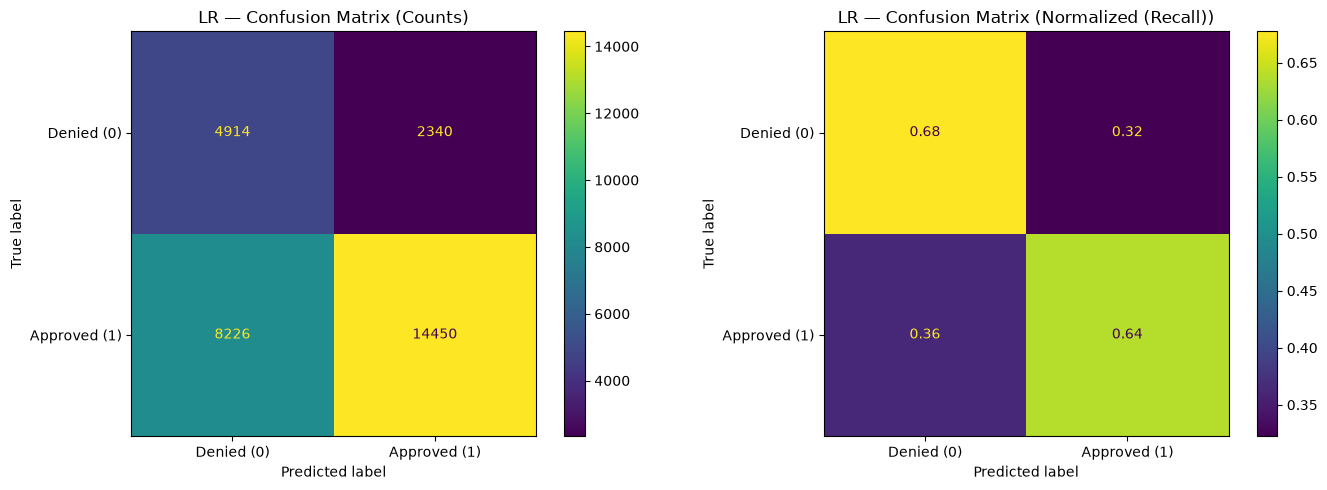

Saved


In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve

lr_pred_test = (lr_prob_test >= lr_threshold).astype(int)

# ── Confusion Matrix (counts + normalized) ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, norm, title in zip(axes, [None, "true"], ["Counts", "Normalized (Recall)"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test.values, lr_pred_test, ax=ax,
        display_labels=["Denied (0)", "Approved (1)"], normalize=norm,
    )
    ax.set_title(f"LR — Confusion Matrix ({title})")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "lr_confusion_matrix.png", dpi=150)
plt.show()
print(f"Saved")

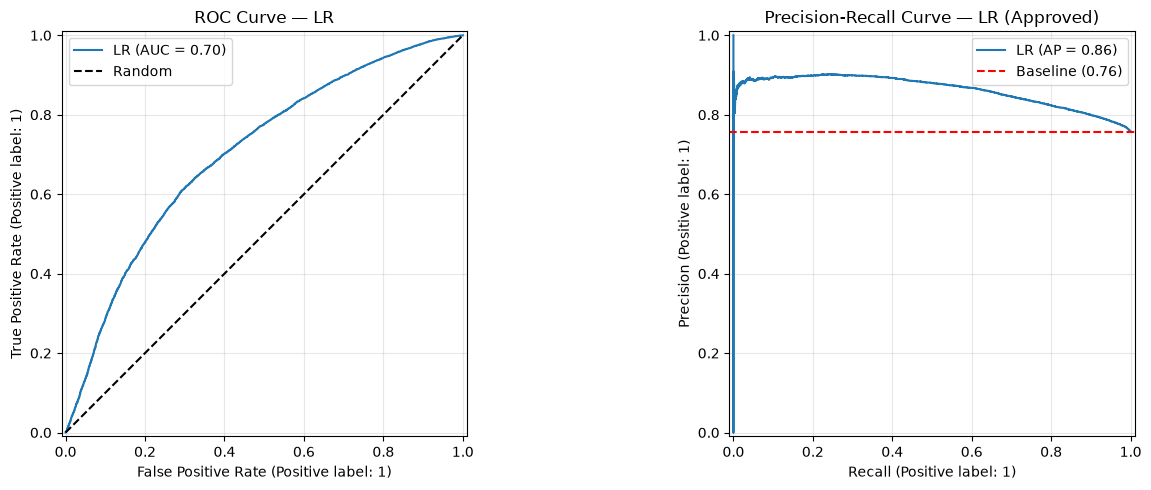

Saved


In [8]:
# ── ROC Curve + Precision-Recall Curve ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC
RocCurveDisplay.from_predictions(y_test.values, lr_prob_test, ax=axes[0], name="LR")
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_title("ROC Curve — LR")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# PR (Approved as positive)
PrecisionRecallDisplay.from_predictions(y_test.values, lr_prob_test, ax=axes[1], name="LR")
baseline_pr = y_test.values.mean()
axes[1].axhline(baseline_pr, color="r", ls="--", label=f"Baseline ({baseline_pr:.2f})")
axes[1].set_title("Precision-Recall Curve — LR (Approved)")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "lr_roc_pr_curves.png", dpi=150)
plt.show()
print(f"Saved")

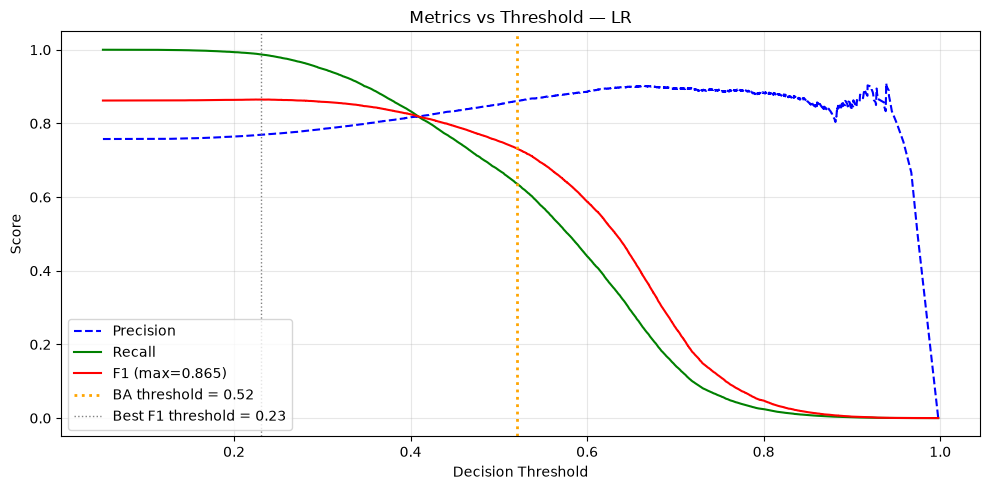

Saved


In [9]:
# ── Precision / Recall / F1 vs Threshold ──
precisions, recalls, thresholds = precision_recall_curve(y_test.values, lr_prob_test)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_f1_thresh = float(thresholds[best_idx]) if best_idx < len(thresholds) else 0.5

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, precisions[:-1], "b--", label="Precision")
ax.plot(thresholds, recalls[:-1], "g-", label="Recall")
ax.plot(thresholds, f1_scores[:-1], "r-", label=f"F1 (max={f1_scores[best_idx]:.3f})")
ax.axvline(lr_threshold, color="orange", ls=":", lw=2, label=f"BA threshold = {lr_threshold}")
ax.axvline(best_f1_thresh, color="gray", ls=":", lw=1, label=f"Best F1 threshold = {best_f1_thresh:.2f}")
ax.set_xlabel("Decision Threshold"); ax.set_ylabel("Score")
ax.set_title("Metrics vs Threshold — LR")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "lr_threshold_analysis.png", dpi=150)
plt.show()
print(f"Saved")

## 5. Lưu model + threshold

In [10]:
joblib.dump(lr_model, MODELS_DIR / "lr_model.pkl")
joblib.dump({
    "threshold": lr_threshold,
    "train_time": lr_train_time,
    "infer_time": lr_infer_time,
    "best_params": best_params_used,
    "best_cv_auc": best_cv_auc,
}, MODELS_DIR / "lr_meta.pkl")

print("✅ Logistic Regression — HOÀN TẤT!")
print(f"   Model    → {MODELS_DIR / 'lr_model.pkl'}")
print(f"   Metadata → {MODELS_DIR / 'lr_meta.pkl'}")
print(f"   Figures  → {list(FIGURES_DIR.glob('lr_*.png'))}")

✅ Logistic Regression — HOÀN TẤT!
   Model    → D:\Projects\DAP391m\data\processed\datasetA\results\models\lr_model.pkl
   Metadata → D:\Projects\DAP391m\data\processed\datasetA\results\models\lr_meta.pkl
   Figures  → [WindowsPath('D:/Projects/DAP391m/data/processed/datasetA/results/figures/lr_confusion_matrix.png'), WindowsPath('D:/Projects/DAP391m/data/processed/datasetA/results/figures/lr_roc_pr_curves.png'), WindowsPath('D:/Projects/DAP391m/data/processed/datasetA/results/figures/lr_threshold_analysis.png')]
